In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression, RANSACRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import statsmodels.api as sm
from sklearn.model_selection import train_test_split

from v2_visualization import plot_sensor_relationship, plot_observed_vs_modeled
from v2_data_preparation import (
    load_and_prepare_data, slice_by_dates, handle_duplicate_values, reindex_daily, filter_by_reflectance, filter_clouds, filter_shadows,
    handle_outliers, calculate_stats_from_random_points, filter_columns, handle_missing_values, attach_spacecraft_column
)

In [18]:
landsat_fp = '../data/processed/satellites/SDH1_L_30m_2012-01-01_2026-10-11.csv'
viirs_fp = '../data/processed/satellites/SDH1_VIIRS_2012_01_2026_10.csv'

start = '2012-01-01'
end = '2026-11-01'

LANDSAT_BLUE = 'blue_median'
LANDSAT_GREEN = 'green_median'
LANDSAT_RED = 'red_median'
LANDSAT_NIR = 'nir_median'
LANDSAT_SWIR1 = 'swir1_median'
LANDSAT_SWIR2 = 'swir2_median'

VIIRS_BLUE = 'Nadir_Reflectance_M3'
VIIRS_GREEN = 'Nadir_Reflectance_M4'
VIIRS_RED = 'Nadir_Reflectance_I1'
VIIRS_NIR = 'Nadir_Reflectance_I2'
VIIRS_SWIR1 = 'Nadir_Reflectance_I3'
VIIRS_SWIR2 = 'Nadir_Reflectance_M11'

landsat_cols = [LANDSAT_BLUE, LANDSAT_GREEN, LANDSAT_RED, LANDSAT_NIR, LANDSAT_SWIR1, LANDSAT_SWIR2]
viirs_cols = [VIIRS_BLUE, VIIRS_GREEN, VIIRS_RED, VIIRS_NIR, VIIRS_SWIR1, VIIRS_SWIR2]

# Format -> 'Final Output Name': ('Landsat_Column_Name', 'VIIRS_Column_Name')
band_mapping = {
    'blue':  (LANDSAT_BLUE,  VIIRS_BLUE),
    'green': (LANDSAT_GREEN, VIIRS_GREEN),
    'red':   (LANDSAT_RED,   VIIRS_RED),
    'nir':   (LANDSAT_NIR,   VIIRS_NIR),
    'swir1': (LANDSAT_SWIR1, VIIRS_SWIR1),
    'swir2': (LANDSAT_SWIR2, VIIRS_SWIR2)
}

In [19]:
landsat = (
    load_and_prepare_data(filepath=landsat_fp)
    .pipe(slice_by_dates, startDate=start, endDate=end)
    #.pipe(filter_by_reflectance)
    .pipe(handle_duplicate_values)      # no tiene efecto
    #.pipe(reindex_daily)               # no deberia ser necesario
    .pipe(handle_outliers, z_thresh=3)
    .pipe(calculate_stats_from_random_points, minPoints=10)
    .pipe(filter_columns, cols_to_keep=landsat_cols)
    #.pipe(filter_clouds, column_name='nir_median', max_threshold=0.7)       # este es aceptable, elimina un par de caso de nubes
    #.pipe(filter_shadows, column_name='swir2_median', min_threshold=0.1)   # no es un buen filtro
)

viirs = (
    load_and_prepare_data(filepath=viirs_fp)
    .pipe(filter_columns, cols_to_keep=viirs_cols)
    .pipe(slice_by_dates, startDate=start, endDate=end)
    .pipe(filter_by_reflectance)
    .pipe(reindex_daily)                # suma una fila
    .pipe(handle_outliers, z_thresh=3)  # hay valores que se vuelven nan
    .pipe(handle_missing_values, method='time')
)

In [20]:
landsat_raw = pd.read_csv(landsat_fp)
landsat_oli = attach_spacecraft_column(landsat, landsat_raw)
landsat_oli = landsat_oli[landsat_oli['Spacecraft'].isin(['LANDSAT_8', 'LANDSAT_9'])]

<Axes: >

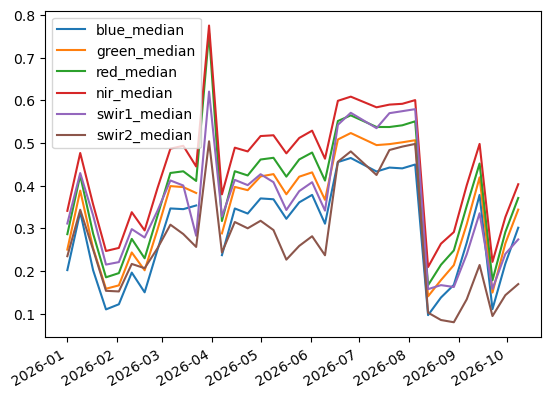

In [21]:
landsat.index = pd.to_datetime(landsat.index)
landsat_clip = landsat[landsat.index.year == 2026]
landsat_clip.plot()

<Axes: xlabel='Timestamps'>

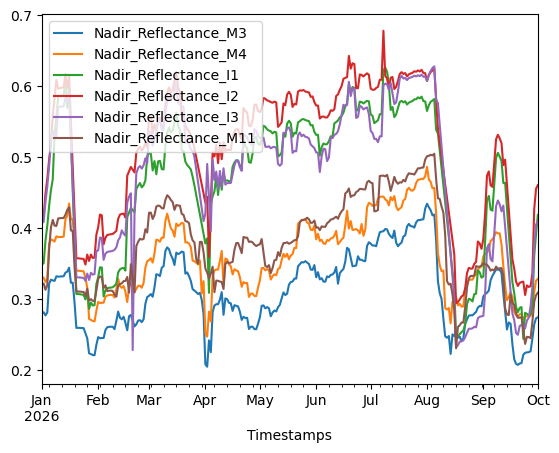

In [22]:
viirs_clip = slice_by_dates(viirs, '2026')
viirs_clip.plot()

Bandas I tienen reflectancias marcadamente mayores que las M

#### Regresion lineal

In [23]:
def get_coincident_data(
        landsat_series: pd.Series,
        modis_series: pd.Series
) -> pd.DataFrame:
    """
    Aligns Landsat and MODIS series by their DatetimeIndex and extracts coincident 
    valid observations.
    """
    # Combine landsat and modis series and rename columns correspondingly
    aligned_df = pd.concat(
        [landsat_series, modis_series], 
        axis=1, 
        keys=['landsat', 'viirs'])

    # Drop NaN values so only coincident dates remain
    return aligned_df.dropna()


def train_linear_regression(
        landsat_modis_df: pd.DataFrame, 
        test_size: float = 0.3, 
        random_state: int = 42,
        verbose_summary: bool = False
):
    """
    Splits the input data into training and testing sets, trains a linear regression 
    model and prints an OLS summary if specified.
    """
    # Define independent and dependent variables
    X = landsat_modis_df[['viirs']].values
    y = landsat_modis_df['landsat'].values
    
    # Split data into train and test subsets
    X_train, X_test, y_train, y_test = train_test_split(
        X, 
        y, 
        test_size=test_size, 
        random_state=random_state
    )
    
    # Train a linear regression model with scikit-learn
    model = LinearRegression()
    model.fit(X_train, y_train)

    # Print a detailed summary of the regression with statsmodels if specified
    if verbose_summary:
        X_train_sm = sm.add_constant(X_train)
        ols_model = sm.OLS(y_train, X_train_sm).fit()
        print(ols_model.summary())

    return model, X_train, X_test, y_train, y_test


def calculate_regression_metrics(
        y_true: np.ndarray,
        y_pred: np.ndarray
) -> dict[str, float]:
    """
    Calculates R2, MAE and RMSE for a pair of observed and predicted arrays
    """
    return {
        'r2': round(float(r2_score(y_true, y_pred)), 3),
        'mae': round(float(mean_absolute_error(y_true, y_pred)), 3),
        'rmse': round(float(np.sqrt(mean_squared_error(y_true, y_pred))), 3)
    }


def predict_using_linear_regression(
       modis_series: pd.Series,
       model: LinearRegression 
) -> pd.Series:
    """
    Applies the trained linear regression model.    
    """
    # Prepare the independent series
    X_predict = modis_series.values.reshape(-1, 1)

    # Apply the trained model to predict the dependent variable
    y_predict = model.predict(X_predict)

    # EVALUAR LA HERENCIA DEL NOMBRE DE LA SERIE Y SU UTILIDAD
    return pd.Series(y_predict, index=modis_series.index, name=modis_series.name)


def calculate_residuals(
        original_series: pd.Series,
        predicted_series: pd.Series,
) -> pd.Series:
    """
    Calculates the residuals between an original and a predicted series.
    """
    residuals = original_series - predicted_series
    return residuals


def anchor_predictions_with_residuals(
    predicted_series: pd.Series,
    residuals: pd.Series,
    daily_index: pd.DatetimeIndex,
    sigma_threshold: float | None = 3.0
):
    """
    Anchors daily predictions to real Landsat observations and smoothly distributes 
    residuals over time, ignoring outliers beyond a defined standard deviation threshold.
    """
    # Reindex residuals to daily frequency
    daily_residuals = residuals.reindex(daily_index)

    # Residual filering operates if sigma threshold is provided
    if sigma_threshold is not None:
        # Define the tolerance range of valid residuals using std dev
        res_mean = residuals.mean()
        res_std = residuals.std()
        lower_limit = res_mean - (sigma_threshold * res_std)
        upper_limit = res_mean + (sigma_threshold * res_std)

        # Fliter residuals out of tolerance range
        outlier_mask = (daily_residuals < lower_limit) | (daily_residuals > upper_limit)
        daily_residuals[outlier_mask] = np.nan

    # Interpolate residuals to avoid sharp changes when anchoring
    # EVALUAR CUANTO SE RELLENA HACIA EL PRINCIPIO Y FINAL CON BFILL Y FFILL
    residuals_interpolated = daily_residuals.interpolate(method='time').bfill().ffill()

    # Anchor the predicted series to the original values by adding the residuals
    anchored_series = predicted_series + residuals_interpolated

    return anchored_series, residuals_interpolated


# ==============================================================================
# PIPELINE
# ==============================================================================

def fuse_sensors(
    modis_df: pd.DataFrame,
    landsat_df: pd.DataFrame,
    band_mapping: dict,
    test_size: float = 0.3,
    sigma_threshold: float | None = 3.0,
    verbose_summary: bool = False,
    verbose_plots: bool = False
) -> dict:
    """
    Main pipeline for fusing satellite data
    """
    # Define a daily index based on the length of the modis data
    daily_index = pd.date_range(
        start=modis_df.index.min(), 
        end=modis_df.index.max(), 
        freq='D')

    # Initialize output dfs and dicts
    predicted_df = pd.DataFrame(index=daily_index)
    anchored_df = pd.DataFrame(index=daily_index)
    residuals_df = pd.DataFrame(index=daily_index)
    interp_residuals_df = pd.DataFrame(index=daily_index)
    models = {}
    metrics = {}

    # Loop through each band defined in the mapping dictionary
    for output_band_name, (landsat_col, modis_col) in band_mapping.items():

        # Safety evaluation
        if landsat_col not in landsat_df.columns or modis_col not in modis_df.columns:
            print(f"Warning: columns for {output_band_name} not found. Skipping.")
            continue

        # Column-wise data extraction
        landsat_series = landsat_df[landsat_col]
        modis_series = modis_df[modis_col]

        # 1. Alignment
        coincident_df = get_coincident_data(
            landsat_series=landsat_series, 
            modis_series=modis_series)
        print(f"\n{'='*50}\nProcessing {output_band_name} ({len(coincident_df)} coincident points)\n{'='*50}")

        # Safety evaluation
        if coincident_df.empty:
            print(f"Warning: No valid coincident dates found for {output_band_name}. Skipping.")
            continue

        # 2. Model training
        model, X_train, X_test, y_train, y_test = train_linear_regression(
            landsat_modis_df=coincident_df,
            test_size=test_size,
            random_state=42,
            verbose_summary=verbose_summary
        )
        models[output_band_name] = model

        # 3. Model evaluation
        y_train_pred = model.predict(X_train)
        y_test_pred = model.predict(X_test)
        metrics[output_band_name] = {
            'train': calculate_regression_metrics(y_train, y_train_pred),
            'test': calculate_regression_metrics(y_test, y_test_pred)
        }
        m = metrics[output_band_name]
        print(f"Train - R2: {m['train']['r2']} | MAE: {m['train']['mae']} | RMSE: {m['train']['rmse']}")
        print(f"Test  - R2: {m['test']['r2']}  | MAE: {m['test']['mae']}  | RMSE: {m['test']['rmse']}")

        # 4. Plotting
        if verbose_plots:
            plot_sensor_relationship(X_train, y_train, output_band_name)
            plot_observed_vs_modeled(y_train, y_train_pred, y_test, y_test_pred, output_band_name)

        # 5. Model application
        predicted_series = predict_using_linear_regression(
            modis_series=modis_series,
            model=model
        )

        # 6. Residuals calculation
        residuals_series = calculate_residuals(
            original_series=landsat_series,
            predicted_series=predicted_series
        )

        # 7. Anchor predictions
        anchored_series, interp_residuals_series = anchor_predictions_with_residuals(
            predicted_series=predicted_series,
            residuals=residuals_series,
            daily_index=daily_index,
            sigma_threshold=sigma_threshold
        )

        # Accumulate results
        predicted_df[output_band_name] = predicted_series
        anchored_df[output_band_name] = anchored_series
        residuals_df[output_band_name] = residuals_series
        interp_residuals_df[output_band_name] = interp_residuals_series

    return {
        'predicted': predicted_df,
        'anchored': anchored_df,
        'residuals': residuals_df,
        'residuals_interpolated': interp_residuals_df,
        'metrics': metrics,
        'models': models
    }

In [24]:
sensor_fusion_results = fuse_sensors(
    modis_df=viirs,
    landsat_df=landsat,
    band_mapping=band_mapping,
    test_size=0.3,
    sigma_threshold=3.0,
    verbose_summary=False,
    verbose_plots=False
)


Processing blue (532 coincident points)
Train - R2: 0.457 | MAE: 0.056 | RMSE: 0.072
Test  - R2: 0.411  | MAE: 0.056  | RMSE: 0.072

Processing green (535 coincident points)
Train - R2: 0.442 | MAE: 0.059 | RMSE: 0.077
Test  - R2: 0.506  | MAE: 0.056  | RMSE: 0.071

Processing red (533 coincident points)
Train - R2: 0.614 | MAE: 0.048 | RMSE: 0.07
Test  - R2: 0.702  | MAE: 0.04  | RMSE: 0.055

Processing nir (536 coincident points)
Train - R2: 0.611 | MAE: 0.046 | RMSE: 0.067
Test  - R2: 0.655  | MAE: 0.044  | RMSE: 0.061

Processing swir1 (536 coincident points)
Train - R2: 0.597 | MAE: 0.055 | RMSE: 0.072
Test  - R2: 0.64  | MAE: 0.056  | RMSE: 0.07

Processing swir2 (536 coincident points)
Train - R2: 0.553 | MAE: 0.06 | RMSE: 0.076
Test  - R2: 0.628  | MAE: 0.06  | RMSE: 0.073


/var/folders/jv/vkj2kxvs7vs4lb9_8bnqgr2h0000gn/T/ipykernel_55257/177378802.py:10: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  aligned_df = pd.concat(
/var/folders/jv/vkj2kxvs7vs4lb9_8bnqgr2h0000gn/T/ipykernel_55257/177378802.py:10: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  aligned_df = pd.concat(
/var/folders/jv/vkj2kxvs7vs4lb9_8bnqgr2h0000gn/T/ipykernel_55257/177378802.py:10: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas 

#### Regresion polinomial

In [25]:
# def train_polynomial_regression(
#     landsat_modis_df: pd.DataFrame,
#     degree: int = 2,
#     test_size: float = 0.3,
#     random_state: int = 42,
#     verbose_summary: bool = False,
# ):
#     """
#     Splits the input data into training and testing sets, trains a polynomial regression
#     pipeline and prints an OLS summary if specified.
#     """
#     # Define independent and dependent variables
#     X = landsat_modis_df[["viirs"]].values
#     y = landsat_modis_df["landsat"].values

#     # Split data into train and test subsets
#     X_train, X_test, y_train, y_test = train_test_split(
#         X, y, test_size=test_size, random_state=random_state
#     )

#     model = Pipeline(
#         [
#             (
#                 "polynomial_features",
#                 PolynomialFeatures(degree=degree, include_bias=False),
#             ),
#             ("linear_regression", LinearRegression()),
#         ]
#     )
#     model.fit(X_train, y_train)

#     # Print a detailed summary of the regression with statsmodels if specified
#     if verbose_summary:
#         # TRANSFORM TRAINING FEATURES USING THE PIPELINE STEP BEFORE PASSING TO STATSMODELS
#         X_train_poly = model.named_steps["polynomial_features"].transform(
#             X_train
#         )
#         X_train_sm = sm.add_constant(X_train_poly)
#         ols_model = sm.OLS(y_train, X_train_sm).fit()
#         print(ols_model.summary())

#     return model, X_train, X_test, y_train, y_test


# def calculate_regression_metrics(
#     y_true: np.ndarray, y_pred: np.ndarray
# ) -> dict[str, float]:
#     """
#     Calculates R2, MAE and RMSE for a pair of observed and predicted arrays
#     """
#     return {
#         "r2": round(float(r2_score(y_true, y_pred)), 3),
#         "mae": round(float(mean_absolute_error(y_true, y_pred)), 3),
#         "rmse": round(float(np.sqrt(mean_squared_error(y_true, y_pred))), 3),
#     }


# def predict_using_polynomial_regression(
#     modis_series: pd.Series,
#     model: Pipeline,
# ) -> pd.Series:
#     """
#     Applies the trained polynomial regression pipeline.
#     """
#     # Prepare the independent series
#     X_predict = modis_series.values.reshape(-1, 1)

#     # Apply the trained model to predict the dependent variable
#     y_predict = model.predict(X_predict)
    
#     return pd.Series(
#         y_predict, index=modis_series.index, name=modis_series.name
#     )


# # UPDATED FUNCTION SIGNATURE TO ACCEPT THE TRAINED PIPELINE MODEL
# def plot_sensor_relationship_poly(
#     X_train: np.ndarray, y_train: np.ndarray, model: Pipeline, band_name: str
# ):
#     """
#     Plots MODIS vs Landsat training data, including the polynomial curve
#     generated by the trained pipeline model.
#     """
#     x_flat = X_train.flatten()

#     # Calculate global minimum and maximum
#     global_min = min(x_flat.min(), y_train.min()) - 0.02
#     global_max = max(x_flat.max(), y_train.max()) + 0.02

#     plt.figure(figsize=(6, 5))

#     # Scatter plot of training data
#     plt.scatter(
#         x_flat,
#         y_train,
#         alpha=0.6,
#         color="#2A9D8F",
#         label="Train set",
#         s=20,
#     )

#     # GENERATE DENSE GRID OF POINTS TO DRAW A SMOOTH POLYNOMIAL CURVE
#     curve_x = np.linspace(x_flat.min(), x_flat.max(), 300).reshape(-1, 1)

#     # USE THE FITTED PIPELINE TO PREDICT VALUES ALONG THE CURVE
#     curve_y = model.predict(curve_x)

#     # PLOT POLYNOMIAL CURVE INSTEAD OF A TWO-POINT STRAIGHT LINE
#     plt.plot(
#         curve_x,
#         curve_y,
#         color="#E76F51",
#         linewidth=2,
#         label="Polynomial fit",
#     )

#     plt.xlim(global_min, global_max)
#     plt.ylim(global_min, global_max)

#     plt.title(f"MODIS vs Landsat relationship - {band_name}")
#     plt.xlabel("MODIS reflectance")
#     plt.ylabel("Landsat reflectance")
#     plt.legend()
#     plt.grid(True, linestyle="-", alpha=0.2)
#     plt.tight_layout()
#     plt.show()


# def fuse_sensors_polynomial(
#     modis_df: pd.DataFrame,
#     landsat_df: pd.DataFrame,
#     band_mapping: dict,
#     # ADDED DEGREE PARAMETER TO PROPAGATE POLYNOMIAL ORDER
#     degree: int = 2,
#     test_size: float = 0.3,
#     verbose_summary: bool = False,
#     verbose_plots: bool = False,
# ) -> dict:
#     """
#     Main pipeline for fusing satellite data using polynomial regression
#     """
#     # Define a daily index based on the length of the modis data
#     daily_index = pd.date_range(
#         start=modis_df.index.min(), end=modis_df.index.max(), freq="D"
#     )

#     # REMOVED ANCHORED_DF AND INTERP_RESIDUALS_DF AS ANCHORING STEP IS OMITTED
#     predicted_df = pd.DataFrame(index=daily_index)
#     residuals_df = pd.DataFrame(index=daily_index)
#     models = {}
#     metrics = {}

#     # Loop through each band defined in the mapping dictionary
#     for output_band_name, (landsat_col, modis_col) in band_mapping.items():

#         # Safety evaluation
#         if (
#             landsat_col not in landsat_df.columns
#             or modis_col not in modis_df.columns
#         ):
#             print(
#                 f"Warning: columns for {output_band_name} not found. Skipping."
#             )
#             continue

#         # Column-wise data extraction
#         landsat_series = landsat_df[landsat_col]
#         modis_series = modis_df[modis_col]

#         # 1. Alignment
#         coincident_df = get_coincident_data(
#             landsat_series=landsat_series, modis_series=modis_series
#         )
#         print(
#             f"\n{'='*50}\nProcessing {output_band_name} ({len(coincident_df)} coincident points)\n{'='*50}"
#         )

#         # Safety evaluation
#         if coincident_df.empty:
#             print(
#                 f"Warning: No valid coincident dates found for {output_band_name}. Skipping."
#             )
#             continue

#         # 2. Model training
#         # UPDATED TO CALL TRAIN_POLYNOMIAL_REGRESSION WITH DEGREE
#         model, X_train, X_test, y_train, y_test = train_polynomial_regression(
#             landsat_modis_df=coincident_df,
#             degree=degree,
#             test_size=test_size,
#             random_state=42,
#             verbose_summary=verbose_summary,
#         )
#         models[output_band_name] = model

#         # 3. Model evaluation
#         y_train_pred = model.predict(X_train)
#         y_test_pred = model.predict(X_test)
#         metrics[output_band_name] = {
#             "train": calculate_regression_metrics(y_train, y_train_pred),
#             "test": calculate_regression_metrics(y_test, y_test_pred),
#         }
#         m = metrics[output_band_name]
#         print(
#             f"Train - R2: {m['train']['r2']} | MAE: {m['train']['mae']} | RMSE: {m['train']['rmse']}"
#         )
#         print(
#             f"Test  - R2: {m['test']['r2']}  | MAE: {m['test']['mae']}  | RMSE: {m['test']['rmse']}"
#         )

#         # 4. Plotting
#         if verbose_plots:
#             plot_sensor_relationship_poly(X_train, y_train, model, output_band_name)
#             plot_observed_vs_modeled(
#                 y_train, y_train_pred, y_test, y_test_pred, output_band_name
#             )

#         # 5. Model application
#         # UPDATED TO CALL PREDICT_USING_POLYNOMIAL_REGRESSION
#         predicted_series = predict_using_polynomial_regression(
#             modis_series=modis_series, model=model
#         )

#         # 6. Residuals calculation
#         residuals_series = calculate_residuals(
#             original_series=landsat_series, predicted_series=predicted_series
#         )

#         # Accumulate results
#         # REMOVED ACCUMULATION OF ANCHORED AND INTERPOLATED RESIDUALS
#         predicted_df[output_band_name] = predicted_series
#         residuals_df[output_band_name] = residuals_series

#     # UPDATED RETURN DICTIONARY WITHOUT ANCHORED OR INTERPOLATED RESIDUAL KEYS
#     return {
#         "predicted": predicted_df,
#         "residuals": residuals_df,
#         "metrics": metrics,
#         "models": models,
#     }

In [26]:
# sensor_fusion_results_poly = fuse_sensors_polynomial(
#     modis_df=viirs,
#     landsat_df=landsat,
#     band_mapping=band_mapping,
#     degree=2,
#     test_size=0.3,
#     verbose_summary=True,
#     verbose_plots=True
# )

El ajuste polinomial de grado 2 y 3 mejoran levemente los resultados en algunas bandas, pero el incremento no justifica la complejización del modelo

#### Regresion lineal RANSAC

In [27]:
# def get_coincident_data(
#     landsat_series: pd.Series, 
#     modis_series: pd.Series
# ) -> pd.DataFrame:
#     """
#     Aligns Landsat and MODIS series by their DatetimeIndex and extracts coincident 
#     valid observations.
#     """
#     # Combine landsat and modis series and rename columns correspondingly
#     aligned_df = pd.concat(
#         [landsat_series, modis_series], 
#         axis=1, 
#         keys=['landsat', 'viirs']
#     )

#     # Drop NaN values so only coincident dates remain
#     return aligned_df.dropna()


# # RENAMED FUNCTION AND REPLACED ESTIMATOR WITH RANSACREGRESSOR
# def train_ransac_regression(
#     landsat_modis_df: pd.DataFrame, 
#     test_size: float = 0.3, 
#     random_state: int = 42,
#     residual_threshold: float | None = None,
#     verbose_summary: bool = False
# ):
#     """
#     Splits the input data into training and testing sets, trains a RANSAC regression 
#     model and prints an OLS summary over detected inliers if specified.
#     """
#     # Define independent and dependent variables
#     X = landsat_modis_df[['viirs']].values
#     y = landsat_modis_df['landsat'].values
    
#     # Split data into train and test subsets
#     X_train, X_test, y_train, y_test = train_test_split(
#         X, 
#         y, 
#         test_size=test_size, 
#         random_state=random_state
#     )
    
#     # TRAIN RANSAC REGRESSOR TO DETECT INLIERS AND FIT THE ROBUST MODEL
#     model = RANSACRegressor(
#         random_state=random_state,
#         residual_threshold=residual_threshold
#     )
#     model.fit(X_train, y_train)

#     # Print a detailed summary of the regression with statsmodels if specified
#     if verbose_summary:
#         # EXTRACT INLIER MASK TO COMPUTE THE SUMMARY EXCLUSIVELY ON INLIER SAMPLES
#         inlier_mask = model.inlier_mask_
#         X_train_inliers = X_train[inlier_mask]
#         y_train_inliers = y_train[inlier_mask]

#         X_train_sm = sm.add_constant(X_train_inliers)
#         ols_model = sm.OLS(y_train_inliers, X_train_sm).fit()
#         print(ols_model.summary())

#     return model, X_train, X_test, y_train, y_test


# def calculate_regression_metrics(
#     y_true: np.ndarray,
#     y_pred: np.ndarray
# ) -> dict[str, float]:
#     """
#     Calculates R2, MAE and RMSE for a pair of observed and predicted arrays
#     """
#     return {
#         'r2': round(float(r2_score(y_true, y_pred)), 3),
#         'mae': round(float(mean_absolute_error(y_true, y_pred)), 3),
#         'rmse': round(float(np.sqrt(mean_squared_error(y_true, y_pred))), 3)
#     }


# # RENAMED FUNCTION AND UPDATED TYPE HINT TO RANSACREGRESSOR
# def predict_using_ransac_regression(
#     modis_series: pd.Series,
#     model: RANSACRegressor 
# ) -> pd.Series:
#     """
#     Applies the trained RANSAC regression model.    
#     """
#     # Prepare the independent series
#     X_predict = modis_series.values.reshape(-1, 1)

#     # Apply the trained model to predict the dependent variable
#     y_predict = model.predict(X_predict)

#     # Return series with original index and name
#     return pd.Series(y_predict, index=modis_series.index, name=modis_series.name)


# def calculate_residuals(
#     original_series: pd.Series,
#     predicted_series: pd.Series,
# ) -> pd.Series:
#     """
#     Calculates the residuals between an original and a predicted series.
#     """
#     residuals = original_series - predicted_series
#     return residuals

# # UPDATED SIGNATURE TO ACCEPT THE TRAINED RANSAC MODEL
# def plot_sensor_relationship_RANSAC(
#     X_train: np.ndarray,
#     y_train: np.ndarray,
#     model: RANSACRegressor,
#     band_name: str,
# ):
#     """
#     Plots MODIS vs Landsat training data separating inliers and outliers,
#     along with the fitted RANSAC regression line.
#     """
#     x_flat = X_train.flatten()

#     # RETRIEVE INLIER AND OUTLIER BOOLEAN MASKS FROM THE FITTED RANSAC MODEL
#     inlier_mask = model.inlier_mask_
#     outlier_mask = np.logical_not(inlier_mask)

#     # Calculate global minimum and maximum
#     global_min = min(x_flat.min(), y_train.min()) - 0.02
#     global_max = max(x_flat.max(), y_train.max()) + 0.02

#     plt.figure(figsize=(6, 5))

#     # SCATTER PLOT EXCLUSIVELY FOR INLIER OBSERVATIONS
#     plt.scatter(
#         x_flat[inlier_mask],
#         y_train[inlier_mask],
#         alpha=0.6,
#         color="#2A9D8F",
#         label="Inliers",
#         s=20,
#     )

#     # SCATTER PLOT HIGHLIGHTING OUTLIER OBSERVATIONS
#     plt.scatter(
#         x_flat[outlier_mask],
#         y_train[outlier_mask],
#         alpha=0.8,
#         color="#E63946",
#         marker="x",
#         label="Outliers",
#         s=40,
#     )

#     # PREDICT THE TREND LINE DIRECTLY FROM THE RANSAC ESTIMATOR
#     line_x = np.linspace(x_flat.min(), x_flat.max(), 100).reshape(-1, 1)
#     line_y = model.predict(line_x)
#     plt.plot(
#         line_x.flatten(),
#         line_y,
#         color="#264653",
#         linewidth=2,
#         label="RANSAC line",
#     )

#     plt.xlim(global_min, global_max)
#     plt.ylim(global_min, global_max)

#     plt.title(f"MODIS vs Landsat relationship - {band_name}")
#     plt.xlabel("MODIS reflectance")
#     plt.ylabel("Landsat reflectance")
#     plt.legend()
#     plt.grid(True, linestyle="-", alpha=0.2)
#     plt.tight_layout()
#     plt.show()

# def fuse_sensors_RANSAC(
#     modis_df: pd.DataFrame,
#     landsat_df: pd.DataFrame,
#     band_mapping: dict,
#     test_size: float = 0.3,
#     # ADDED RESIDUAL_THRESHOLD PARAMETER FOR RANSAC INLIER SEPARATION
#     residual_threshold: float | None = None,
#     verbose_summary: bool = False,
#     verbose_plots: bool = False
# ) -> dict:
#     """
#     Main pipeline for fusing satellite data using RANSAC regression
#     """
#     # Define a daily index based on the length of the modis data
#     daily_index = pd.date_range(
#         start=modis_df.index.min(), 
#         end=modis_df.index.max(), 
#         freq='D'
#     )

#     # Initialize output dfs and dicts
#     predicted_df = pd.DataFrame(index=daily_index)
#     residuals_df = pd.DataFrame(index=daily_index)
#     models = {}
#     metrics = {}

#     # Loop through each band defined in the mapping dictionary
#     for output_band_name, (landsat_col, modis_col) in band_mapping.items():

#         # Safety evaluation
#         if landsat_col not in landsat_df.columns or modis_col not in modis_df.columns:
#             print(f"Warning: columns for {output_band_name} not found. Skipping.")
#             continue

#         # Column-wise data extraction
#         landsat_series = landsat_df[landsat_col]
#         modis_series = modis_df[modis_col]

#         # 1. Alignment
#         coincident_df = get_coincident_data(
#             landsat_series=landsat_series, 
#             modis_series=modis_series
#         )
#         print(f"\n{'='*50}\nProcessing {output_band_name} ({len(coincident_df)} coincident points)\n{'='*50}")

#         # Safety evaluation
#         if coincident_df.empty:
#             print(f"Warning: No valid coincident dates found for {output_band_name}. Skipping.")
#             continue

#         # 2. Model training
#         # UPDATED TRAINING CALL TO USE TRAIN_RANSAC_REGRESSION
#         model, X_train, X_test, y_train, y_test = train_ransac_regression(
#             landsat_modis_df=coincident_df,
#             test_size=test_size,
#             random_state=42,
#             residual_threshold=residual_threshold,
#             verbose_summary=verbose_summary
#         )
#         models[output_band_name] = model

#         # 3. Model evaluation
#         y_train_pred = model.predict(X_train)
#         y_test_pred = model.predict(X_test)
#         metrics[output_band_name] = {
#             'train': calculate_regression_metrics(y_train, y_train_pred),
#             'test': calculate_regression_metrics(y_test, y_test_pred)
#         }
#         m = metrics[output_band_name]
#         print(f"Train - R2: {m['train']['r2']} | MAE: {m['train']['mae']} | RMSE: {m['train']['rmse']}")
#         print(f"Test  - R2: {m['test']['r2']}  | MAE: {m['test']['mae']}  | RMSE: {m['test']['rmse']}")

#         # 4. Plotting
#         if verbose_plots:
#             plot_sensor_relationship_RANSAC(X_train, y_train, model, output_band_name)
#             plot_observed_vs_modeled(y_train, y_train_pred, y_test, y_test_pred, output_band_name)

#         # 5. Model application
#         # UPDATED APPLICATION CALL TO USE PREDICT_USING_RANSAC_REGRESSION
#         predicted_series = predict_using_ransac_regression(
#             modis_series=modis_series,
#             model=model
#         )

#         # 6. Residuals calculation
#         residuals_series = calculate_residuals(
#             original_series=landsat_series,
#             predicted_series=predicted_series
#         )

#         # Accumulate results
#         predicted_df[output_band_name] = predicted_series
#         residuals_df[output_band_name] = residuals_series

#     return {
#         'predicted': predicted_df,
#         'residuals': residuals_df,
#         'metrics': metrics,
#         'models': models
#     }

In [28]:
# results_RANSAC = fuse_sensors_RANSAC(
#     modis_df=viirs,
#     landsat_df=landsat,
#     band_mapping=band_mapping,
#     test_size=0.3,
#     residual_threshold=0.15,
#     verbose_summary=False,
#     verbose_plots=True
# )

#### Huber regression

In [29]:
# from sklearn.linear_model import HuberRegressor


# def get_coincident_data(
#     landsat_series: pd.Series, 
#     modis_series: pd.Series
# ) -> pd.DataFrame:
#     """
#     Aligns Landsat and MODIS series by their DatetimeIndex and extracts coincident 
#     valid observations.
#     """
#     # Combine landsat and modis series and rename columns correspondingly
#     aligned_df = pd.concat(
#         [landsat_series, modis_series], 
#         axis=1, 
#         keys=['landsat', 'viirs']
#     )

#     # Drop NaN values so only coincident dates remain
#     return aligned_df.dropna()


# # RENAMED TRAINING FUNCTION AND ADAPTED ESTIMATOR TO HUBERREGRESSOR
# def train_huber_regression(
#     landsat_modis_df: pd.DataFrame, 
#     test_size: float = 0.3, 
#     random_state: int = 42,
#     # ADDED EPSILON AND ALPHA PARAMETERS FOR HUBER LOSS AND REGULARIZATION
#     epsilon: float = 1.35,
#     alpha: float = 0.0001,
#     verbose_summary: bool = False
# ):
#     """
#     Splits the input data into training and testing sets, trains a Huber regression 
#     model and prints an OLS summary over non-outlier samples if specified.
#     """
#     # Define independent and dependent variables
#     X = landsat_modis_df[['viirs']].values
#     y = landsat_modis_df['landsat'].values
    
#     # Split data into train and test subsets
#     X_train, X_test, y_train, y_test = train_test_split(
#         X, 
#         y, 
#         test_size=test_size, 
#         random_state=random_state
#     )
    
#     # FIT HUBER REGRESSOR WITH SMOOTH LINEAR LOSS FOR OUTLIERS
#     model = HuberRegressor(
#         epsilon=epsilon,
#         alpha=alpha
#     )
#     model.fit(X_train, y_train)

#     # Print a detailed summary of the regression with statsmodels if specified
#     if verbose_summary:
#         # EXTRACT INLIER MASK FROM HUBER OUTLIERS BOOLEAN ATTRIBUTE
#         inlier_mask = np.logical_not(model.outliers_)
#         X_train_inliers = X_train[inlier_mask]
#         y_train_inliers = y_train[inlier_mask]

#         X_train_sm = sm.add_constant(X_train_inliers)
#         ols_model = sm.OLS(y_train_inliers, X_train_sm).fit()
#         print(ols_model.summary())

#     return model, X_train, X_test, y_train, y_test


# def calculate_regression_metrics(
#     y_true: np.ndarray,
#     y_pred: np.ndarray
# ) -> dict[str, float]:
#     """
#     Calculates R2, MAE and RMSE for a pair of observed and predicted arrays
#     """
#     return {
#         'r2': round(float(r2_score(y_true, y_pred)), 3),
#         'mae': round(float(mean_absolute_error(y_true, y_pred)), 3),
#         'rmse': round(float(np.sqrt(mean_squared_error(y_true, y_pred))), 3)
#     }


# # RENAMED FUNCTION AND UPDATED TYPE HINT TO HUBERREGRESSOR
# def predict_using_huber_regression(
#     modis_series: pd.Series,
#     model: HuberRegressor 
# ) -> pd.Series:
#     """
#     Applies the trained Huber regression model.    
#     """
#     # Prepare the independent series
#     X_predict = modis_series.values.reshape(-1, 1)

#     # Apply the trained model to predict the dependent variable
#     y_predict = model.predict(X_predict)

#     # Return series with original index and name
#     return pd.Series(y_predict, index=modis_series.index, name=modis_series.name)


# def calculate_residuals(
#     original_series: pd.Series,
#     predicted_series: pd.Series,
# ) -> pd.Series:
#     """
#     Calculates the residuals between an original and a predicted series.
#     """
#     residuals = original_series - predicted_series
#     return residuals


# # UPDATED SENSOR RELATIONSHIP PLOT FOR HUBERREGRESSOR
# def plot_sensor_relationship(
#     X_train: np.ndarray,
#     y_train: np.ndarray,
#     model: HuberRegressor,
#     band_name: str
# ):
#     """
#     Plots MODIS vs Landsat training data separating inliers and outliers,
#     along with the fitted Huber regression line.
#     """
#     x_flat = X_train.flatten()

#     # RETRIEVE OUTLIER AND INLIER MASKS FROM THE FITTED HUBER MODEL
#     outlier_mask = model.outliers_
#     inlier_mask = np.logical_not(outlier_mask)

#     # Calculate global minimum and maximum
#     global_min = min(x_flat.min(), y_train.min()) - 0.02
#     global_max = max(x_flat.max(), y_train.max()) + 0.02

#     plt.figure(figsize=(6, 5))

#     # Scatter plot of inlier observations
#     plt.scatter(
#         x_flat[inlier_mask],
#         y_train[inlier_mask],
#         alpha=0.6,
#         color='#2A9D8F',
#         label='Inliers',
#         s=20
#     )

#     # Scatter plot of outlier observations identified by HuberRegressor
#     plt.scatter(
#         x_flat[outlier_mask],
#         y_train[outlier_mask],
#         alpha=0.8,
#         color='#E63946',
#         marker='x',
#         label='Outliers',
#         s=40
#     )

#     # PREDICT AND PLOT THE REGRESSION LINE FROM HUBERREGRESSOR
#     line_x = np.linspace(x_flat.min(), x_flat.max(), 100).reshape(-1, 1)
#     line_y = model.predict(line_x)
#     plt.plot(
#         line_x.flatten(),
#         line_y,
#         color='#264653',
#         linewidth=2,
#         label='Huber line'
#     )

#     plt.xlim(global_min, global_max)
#     plt.ylim(global_min, global_max)

#     plt.title(f'MODIS vs Landsat relationship - {band_name}')
#     plt.xlabel('MODIS reflectance')
#     plt.ylabel('Landsat reflectance')
#     plt.legend()
#     plt.grid(True, linestyle='-', alpha=0.2)
#     plt.tight_layout()
#     plt.show()


# def fuse_sensors_huber(
#     modis_df: pd.DataFrame,
#     landsat_df: pd.DataFrame,
#     band_mapping: dict,
#     test_size: float = 0.3,
#     # REPLACED RESIDUAL_THRESHOLD WITH EPSILON AND ALPHA PARAMETERS
#     epsilon: float = 1.35,
#     alpha: float = 0.0001,
#     verbose_summary: bool = False,
#     verbose_plots: bool = False
# ) -> dict:
#     """
#     Main pipeline for fusing satellite data using Huber regression
#     """
#     # Define a daily index based on the length of the modis data
#     daily_index = pd.date_range(
#         start=modis_df.index.min(), 
#         end=modis_df.index.max(), 
#         freq='D'
#     )

#     # Initialize output dfs and dicts
#     predicted_df = pd.DataFrame(index=daily_index)
#     residuals_df = pd.DataFrame(index=daily_index)
#     models = {}
#     metrics = {}

#     # Loop through each band defined in the mapping dictionary
#     for output_band_name, (landsat_col, modis_col) in band_mapping.items():

#         # Safety evaluation
#         if landsat_col not in landsat_df.columns or modis_col not in modis_df.columns:
#             print(f"Warning: columns for {output_band_name} not found. Skipping.")
#             continue

#         # Column-wise data extraction
#         landsat_series = landsat_df[landsat_col]
#         modis_series = modis_df[modis_col]

#         # 1. Alignment
#         coincident_df = get_coincident_data(
#             landsat_series=landsat_series, 
#             modis_series=modis_series
#         )
#         print(f"\n{'='*50}\nProcessing {output_band_name} ({len(coincident_df)} coincident points)\n{'='*50}")

#         # Safety evaluation
#         if coincident_df.empty:
#             print(f"Warning: No valid coincident dates found for {output_band_name}. Skipping.")
#             continue

#         # 2. Model training
#         # UPDATED CALL TO USE TRAIN_HUBER_REGRESSION
#         model, X_train, X_test, y_train, y_test = train_huber_regression(
#             landsat_modis_df=coincident_df,
#             test_size=test_size,
#             random_state=42,
#             epsilon=epsilon,
#             alpha=alpha,
#             verbose_summary=verbose_summary
#         )
#         models[output_band_name] = model

#         # 3. Model evaluation
#         y_train_pred = model.predict(X_train)
#         y_test_pred = model.predict(X_test)
#         metrics[output_band_name] = {
#             'train': calculate_regression_metrics(y_train, y_train_pred),
#             'test': calculate_regression_metrics(y_test, y_test_pred)
#         }
#         m = metrics[output_band_name]
#         print(f"Train - R2: {m['train']['r2']} | MAE: {m['train']['mae']} | RMSE: {m['train']['rmse']}")
#         print(f"Test  - R2: {m['test']['r2']}  | MAE: {m['test']['mae']}  | RMSE: {m['test']['rmse']}")

#         # 4. Plotting
#         if verbose_plots:
#             # PASSED FITTED HUBER MODEL TO SENSOR RELATIONSHIP PLOT
#             plot_sensor_relationship(X_train, y_train, model, output_band_name)
#             plot_observed_vs_modeled(y_train, y_train_pred, y_test, y_test_pred, output_band_name)

#         # 5. Model application
#         # UPDATED PREDICTION CALL TO USE PREDICT_USING_HUBER_REGRESSION
#         predicted_series = predict_using_huber_regression(
#             modis_series=modis_series,
#             model=model
#         )

#         # 6. Residuals calculation
#         residuals_series = calculate_residuals(
#             original_series=landsat_series,
#             predicted_series=predicted_series
#         )

#         # Accumulate results
#         predicted_df[output_band_name] = predicted_series
#         residuals_df[output_band_name] = residuals_series

#     return {
#         'predicted': predicted_df,
#         'residuals': residuals_df,
#         'metrics': metrics,
#         'models': models
#     }

In [30]:
# results_huber = fuse_sensors_huber(
#     modis_df=viirs,
#     landsat_df=landsat,
#     band_mapping=band_mapping,
#     test_size=0.3,
#     epsilon=3,
#     alpha=0.0001,
#     verbose_summary=False,
#     verbose_plots=True
# )